# Task Performance Mean +/- SD by Modality

This notebook computes task-performance summaries for both modalities:
- `TextualAttack/user performance` (Text-Only)
- `MultiModalAttack/user performance` (Multi-Modal)

It reports **participant-level** metrics first, then modality-level **mean +/- SD** across participants.

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = Path.cwd()

PERF_DIRS = {
    "Text-Only": BASE_DIR / "TextualAttack" / "user performance",
    "Multi-Modal": BASE_DIR / "MultiModalAttack" / "user performance",
}

for modality, folder in PERF_DIRS.items():
    print(f"{modality}: {folder} | exists={folder.exists()}")

Text-Only: c:\Users\nahmed25\PhD\ISMAR26_Engagement\TextualAttack\user performance | exists=True
Multi-Modal: c:\Users\nahmed25\PhD\ISMAR26_Engagement\MultiModalAttack\user performance | exists=True


In [4]:
def extract_participant_id(file_path: Path):
    match = re.match(r"(\d+)_", file_path.name)
    return int(match.group(1)) if match else None


def to_bool01(series: pd.Series) -> pd.Series:
    if series.dtype == bool:
        return series.astype(float)
    mapping = {"true": 1, "false": 0, "1": 1, "0": 0}
    normalized = series.astype(str).str.strip().str.lower().map(mapping)
    return pd.to_numeric(normalized, errors="coerce")


def get_column(df: pd.DataFrame, preferred_name: str, fallback_idx: int) -> pd.Series:
    if preferred_name in df.columns:
        return df[preferred_name]
    if df.shape[1] > fallback_idx:
        return df.iloc[:, fallback_idx]
    return pd.Series([np.nan] * len(df))


def get_col_by_idx(df: pd.DataFrame, idx: int) -> pd.Series:
    if df.shape[1] > idx:
        return df.iloc[:, idx]
    return pd.Series([np.nan] * len(df))


def attempt_quality_score(series: pd.Series) -> float:
    valid = series.dropna()
    if valid.empty:
        return -1.0
    plausible = ((valid >= 0) & (valid <= 10)).mean()
    integer_like = np.isclose(valid, np.round(valid)).mean()
    return float(plausible + integer_like)


def load_modality_performance(folder: Path, modality: str) -> pd.DataFrame:
    files = sorted(folder.glob("*_activityData.csv"))
    print(f"{modality}: found {len(files)} performance files")
    all_rows = []

    for file_path in files:
        participant_id = extract_participant_id(file_path)
        if participant_id is None:
            continue

        try:
            df = pd.read_csv(file_path)
        except Exception as exc:
            print(f"  Skipping {file_path.name}: {exc}")
            continue

        df.columns = [str(c).strip() for c in df.columns]

        # Prefer StepName for stable activity typing across both modalities.
        activity = get_column(df, "StepName", 0).astype(str).str.strip()

        # Multi-Modal files carry the boolean correctness at positional index 2.
        named_correct = to_bool01(get_column(df, "IsCorrect", 2))
        positional_correct = to_bool01(get_col_by_idx(df, 2))
        if positional_correct.notna().mean() > named_correct.notna().mean():
            is_correct = positional_correct
        else:
            is_correct = named_correct

        # Multi-Modal logs often have attempts at positional index 4, not in the named column.
        named_attempts = pd.to_numeric(get_column(df, "NumberOfAttempts", 4), errors="coerce")
        positional_attempts = pd.to_numeric(get_col_by_idx(df, 4), errors="coerce")
        if attempt_quality_score(positional_attempts) > attempt_quality_score(named_attempts):
            attempts = positional_attempts
        else:
            attempts = named_attempts

        standardized = pd.DataFrame({
            "ParticipantID": participant_id,
            "Modality": modality,
            "ActivityType": activity,
            "IsCorrect01": is_correct,
            "NumberOfAttempts": attempts,
        })

        standardized = standardized.dropna(subset=["IsCorrect01", "NumberOfAttempts"])
        standardized = standardized[standardized["NumberOfAttempts"] >= 1].copy()
        standardized = standardized[standardized["ActivityType"] != ""].copy()

        all_rows.append(standardized)

    if not all_rows:
        return pd.DataFrame(columns=["ParticipantID", "Modality", "ActivityType", "IsCorrect01", "NumberOfAttempts"])

    return pd.concat(all_rows, ignore_index=True)

In [5]:
perf = pd.concat(
    [load_modality_performance(folder=path, modality=modality) for modality, path in PERF_DIRS.items()],
    ignore_index=True,
)

if perf.empty:
    raise ValueError("No valid task performance rows found. Check folder paths and CSV schemas.")

print("Combined rows:", len(perf))
print(perf.groupby("Modality")["ParticipantID"].nunique().rename("Participants"))
display(perf.head())

Text-Only: found 15 performance files
Multi-Modal: found 14 performance files
Combined rows: 728
Modality
Multi-Modal    14
Text-Only      15
Name: Participants, dtype: int64


,ParticipantID,Modality,ActivityType,IsCorrect01,NumberOfAttempts
0,700,Text-Only,Navigation Activity,1.0,1.0
1,700,Text-Only,Discovery Activity,1.0,4.0
2,700,Text-Only,Locate & Select Activity,0.0,3.0
3,700,Text-Only,Insert Title,1.0,1.0
4,700,Text-Only,Discovery Activity,1.0,2.0


In [6]:
perf["FirstAttemptCorrect"] = ((perf["IsCorrect01"] == 1) & (perf["NumberOfAttempts"] == 1)).astype(float)

participant_summary = (
    perf.groupby(["Modality", "ParticipantID"], as_index=False)
    .agg(
        Accuracy=("IsCorrect01", "mean"),
        FirstAttemptAccuracy=("FirstAttemptCorrect", "mean"),
        MeanAttempts=("NumberOfAttempts", "mean"),
        NActivities=("IsCorrect01", "count"),
    )
)

print("Participant-level summary (first rows):")
display(participant_summary.head())

Participant-level summary (first rows):


,Modality,ParticipantID,Accuracy,FirstAttemptAccuracy,MeanAttempts,NActivities
0,Multi-Modal,600,0.875000,0.708333,1.416667,24
1,Multi-Modal,601,0.875000,0.625000,1.583333,24
2,Multi-Modal,602,0.772727,0.636364,1.227273,22
3,Multi-Modal,605,0.900000,0.750000,1.300000,20
4,Multi-Modal,608,0.800000,0.640000,1.240000,25


In [7]:
modality_summary = (
    participant_summary.groupby("Modality", as_index=False)
    .agg(
        Participants=("ParticipantID", "nunique"),
        Accuracy_Mean=("Accuracy", "mean"),
        Accuracy_SD=("Accuracy", lambda x: float(np.std(x, ddof=1)) if len(x) > 1 else np.nan),
        FirstAttempt_Mean=("FirstAttemptAccuracy", "mean"),
        FirstAttempt_SD=("FirstAttemptAccuracy", lambda x: float(np.std(x, ddof=1)) if len(x) > 1 else np.nan),
        MeanAttempts_Mean=("MeanAttempts", "mean"),
        MeanAttempts_SD=("MeanAttempts", lambda x: float(np.std(x, ddof=1)) if len(x) > 1 else np.nan),
        ActivitiesPerParticipant_Mean=("NActivities", "mean"),
        ActivitiesPerParticipant_SD=("NActivities", lambda x: float(np.std(x, ddof=1)) if len(x) > 1 else np.nan),
    )
    .sort_values("Modality")
    .reset_index(drop=True)
)

display_table = modality_summary.copy()
percent_cols = ["Accuracy_Mean", "Accuracy_SD", "FirstAttempt_Mean", "FirstAttempt_SD"]
display_table[percent_cols] = display_table[percent_cols] * 100

display_table = display_table.round({
    "Accuracy_Mean": 2,
    "Accuracy_SD": 2,
    "FirstAttempt_Mean": 2,
    "FirstAttempt_SD": 2,
    "MeanAttempts_Mean": 2,
    "MeanAttempts_SD": 2,
    "ActivitiesPerParticipant_Mean": 2,
    "ActivitiesPerParticipant_SD": 2,
})

print("Modality-level mean +/- SD across participants:")
display(display_table)

for _, row in display_table.iterrows():
    print(
        f"{row['Modality']}: Accuracy={row['Accuracy_Mean']}% +/- {row['Accuracy_SD']} | "
        f"First-attempt={row['FirstAttempt_Mean']}% +/- {row['FirstAttempt_SD']} | "
        f"Mean attempts={row['MeanAttempts_Mean']} +/- {row['MeanAttempts_SD']}"
    )

Modality-level mean +/- SD across participants:


,Modality,Participants,Accuracy_Mean,Accuracy_SD,FirstAttempt_Mean,FirstAttempt_SD,MeanAttempts_Mean,MeanAttempts_SD,ActivitiesPerParticipant_Mean,ActivitiesPerParticipant_SD
0,Multi-Modal,14,80.80,11.9,66.27,11.81,1.39,0.32,21.71,3.07
1,Text-Only,15,82.28,11.2,65.66,8.33,1.36,0.10,28.27,7.62


Multi-Modal: Accuracy=80.8% +/- 11.9 | First-attempt=66.27% +/- 11.81 | Mean attempts=1.39 +/- 0.32
Text-Only: Accuracy=82.28% +/- 11.2 | First-attempt=65.66% +/- 8.33 | Mean attempts=1.36 +/- 0.1


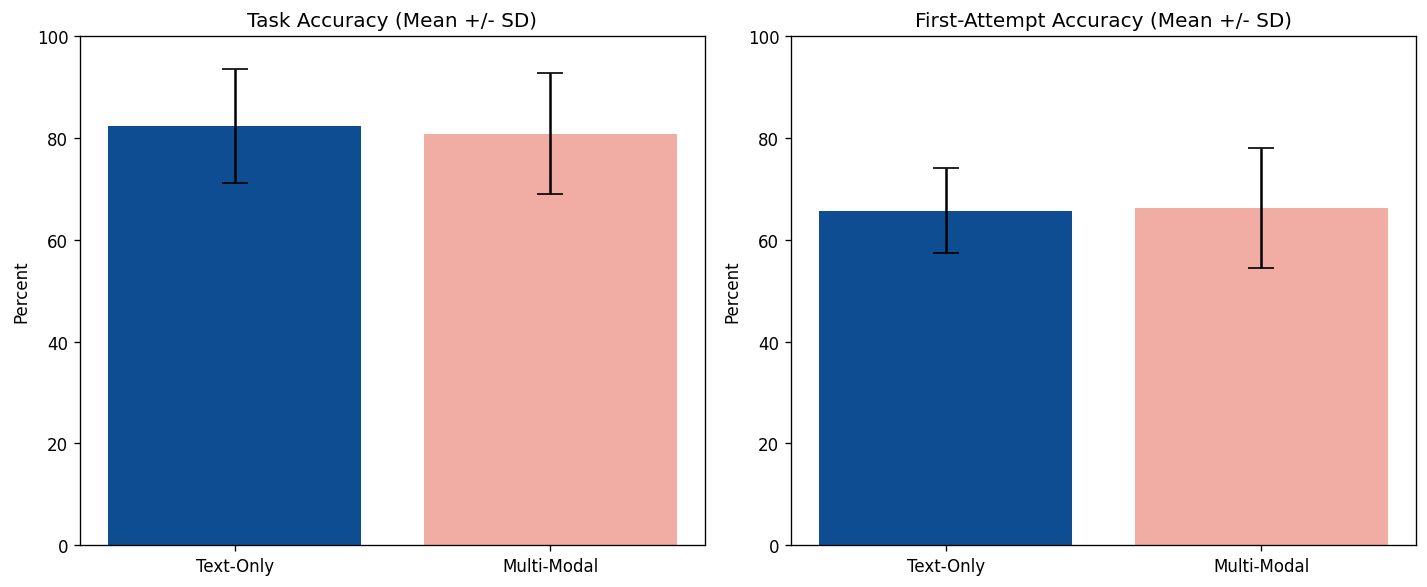

In [8]:
plot_df = modality_summary.set_index("Modality").reindex(["Text-Only", "Multi-Modal"]).dropna(how="all").reset_index()
colors = ["#0F4D92", "#F1ACA4"][:len(plot_df)]
x = np.arange(len(plot_df))

fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=120)

axes[0].bar(
    x,
    plot_df["Accuracy_Mean"] * 100,
    yerr=plot_df["Accuracy_SD"] * 100,
    capsize=8,
    color=colors,
)
axes[0].set_title("Task Accuracy (Mean +/- SD)")
axes[0].set_ylabel("Percent")
axes[0].set_xticks(x)
axes[0].set_xticklabels(plot_df["Modality"])
axes[0].set_ylim(0, 100)

axes[1].bar(
    x,
    plot_df["FirstAttempt_Mean"] * 100,
    yerr=plot_df["FirstAttempt_SD"] * 100,
    capsize=8,
    color=colors,
)
axes[1].set_title("First-Attempt Accuracy (Mean +/- SD)")
axes[1].set_ylabel("Percent")
axes[1].set_xticks(x)
axes[1].set_xticklabels(plot_df["Modality"])
axes[1].set_ylim(0, 100)

plt.tight_layout()
plt.show()

In [9]:
# Participant-level descriptive statistics by modality
if "participant_summary" not in globals():
    raise RuntimeError("participant_summary not found. Run the earlier cells first.")

metrics = ["Accuracy", "FirstAttemptAccuracy", "MeanAttempts", "NActivities"]
records = []

for modality_name, subset in participant_summary.groupby("Modality"):
    stats = subset[metrics].agg(["count", "mean", "std", "median", "min", "max"]).T
    stats = stats.reset_index().rename(columns={"index": "Metric", "count": "N"})
    stats.insert(0, "Modality", modality_name)

    # Show accuracy metrics as percent for readability.
    pct_metrics = {"Accuracy", "FirstAttemptAccuracy"}
    pct_mask = stats["Metric"].isin(pct_metrics)
    for col in ["mean", "std", "median", "min", "max"]:
        stats.loc[pct_mask, col] = stats.loc[pct_mask, col] * 100

    records.append(stats)

descriptive_stats_by_modality = pd.concat(records, ignore_index=True)
descriptive_stats_by_modality = descriptive_stats_by_modality.round({
    "N": 0,
    "mean": 2,
    "std": 2,
    "median": 2,
    "min": 2,
    "max": 2,
})

display(descriptive_stats_by_modality)

for modality_name in descriptive_stats_by_modality["Modality"].unique():
    print(f"\n{modality_name}")
    display(descriptive_stats_by_modality[descriptive_stats_by_modality["Modality"] == modality_name])

,Modality,Metric,N,mean,std,median,min,max
0,Multi-Modal,Accuracy,14.0,80.80,11.90,83.67,57.89,95.65
1,Multi-Modal,FirstAttemptAccuracy,14.0,66.27,11.81,65.33,44.00,88.24
2,Multi-Modal,MeanAttempts,14.0,1.39,0.32,1.31,1.12,2.40
3,Multi-Modal,NActivities,14.0,21.71,3.07,22.50,16.00,25.00
4,Text-Only,Accuracy,15.0,82.28,11.20,85.00,61.11,96.00
5,Text-Only,FirstAttemptAccuracy,15.0,65.66,8.33,66.67,50.00,76.32
6,Text-Only,MeanAttempts,15.0,1.36,0.10,1.37,1.16,1.52
7,Text-Only,NActivities,15.0,28.27,7.62,25.00,18.00,45.00



Multi-Modal


,Modality,Metric,N,mean,std,median,min,max
0,Multi-Modal,Accuracy,14.0,80.80,11.90,83.67,57.89,95.65
1,Multi-Modal,FirstAttemptAccuracy,14.0,66.27,11.81,65.33,44.00,88.24
2,Multi-Modal,MeanAttempts,14.0,1.39,0.32,1.31,1.12,2.40
3,Multi-Modal,NActivities,14.0,21.71,3.07,22.50,16.00,25.00



Text-Only


,Modality,Metric,N,mean,std,median,min,max
4,Text-Only,Accuracy,15.0,82.28,11.20,85.00,61.11,96.00
5,Text-Only,FirstAttemptAccuracy,15.0,65.66,8.33,66.67,50.00,76.32
6,Text-Only,MeanAttempts,15.0,1.36,0.10,1.37,1.16,1.52
7,Text-Only,NActivities,15.0,28.27,7.62,25.00,18.00,45.00


In [10]:
# Descriptive statistics by activity type within each modality
if "perf" not in globals():
    raise RuntimeError("perf not found. Run earlier cells first.")

activity_perf = perf.copy()
activity_perf["FirstAttemptCorrect"] = (
    (activity_perf["IsCorrect01"] == 1) & (activity_perf["NumberOfAttempts"] == 1)
).astype(float)

# Participant-level metrics for each activity type
participant_activity_summary = (
    activity_perf.groupby(["Modality", "ActivityType", "ParticipantID"], as_index=False)
    .agg(
        Accuracy=("IsCorrect01", "mean"),
        FirstAttemptAccuracy=("FirstAttemptCorrect", "mean"),
        MeanAttempts=("NumberOfAttempts", "mean"),
        NActivities=("IsCorrect01", "count"),
    )
)

# Descriptive statistics across participants, per modality and activity
activity_type_descriptive_stats = (
    participant_activity_summary.groupby(["Modality", "ActivityType"], as_index=False)
    .agg(
        Participants=("ParticipantID", "nunique"),
        Accuracy_Mean=("Accuracy", "mean"),
        Accuracy_SD=("Accuracy", lambda x: float(np.std(x, ddof=1)) if len(x) > 1 else np.nan),
        FirstAttempt_Mean=("FirstAttemptAccuracy", "mean"),
        FirstAttempt_SD=("FirstAttemptAccuracy", lambda x: float(np.std(x, ddof=1)) if len(x) > 1 else np.nan),
        MeanAttempts_Mean=("MeanAttempts", "mean"),
        MeanAttempts_SD=("MeanAttempts", lambda x: float(np.std(x, ddof=1)) if len(x) > 1 else np.nan),
        NActivities_Mean=("NActivities", "mean"),
        NActivities_SD=("NActivities", lambda x: float(np.std(x, ddof=1)) if len(x) > 1 else np.nan),
    )
    .sort_values(["Modality", "ActivityType"])
    .reset_index(drop=True)
)

# Convert accuracy-style metrics to percent
pct_cols = ["Accuracy_Mean", "Accuracy_SD", "FirstAttempt_Mean", "FirstAttempt_SD"]
activity_type_descriptive_stats[pct_cols] = activity_type_descriptive_stats[pct_cols] * 100

activity_type_descriptive_stats = activity_type_descriptive_stats.round({
    "Accuracy_Mean": 2,
    "Accuracy_SD": 2,
    "FirstAttempt_Mean": 2,
    "FirstAttempt_SD": 2,
    "MeanAttempts_Mean": 2,
    "MeanAttempts_SD": 2,
    "NActivities_Mean": 2,
    "NActivities_SD": 2,
})

print("Participant-level descriptive statistics by ActivityType and Modality:")
display(activity_type_descriptive_stats)

for modality_name in activity_type_descriptive_stats["Modality"].unique():
    print(f"\n{modality_name}")
    display(
        activity_type_descriptive_stats[
            activity_type_descriptive_stats["Modality"] == modality_name
        ]
    )

Participant-level descriptive statistics by ActivityType and Modality:


,Modality,ActivityType,Participants,Accuracy_Mean,Accuracy_SD,FirstAttempt_Mean,FirstAttempt_SD,MeanAttempts_Mean,MeanAttempts_SD,NActivities_Mean,NActivities_SD
0,Multi-Modal,Discovery Activity,13,100.00,0.00,58.23,15.68,1.79,0.28,6.31,2.72
1,Multi-Modal,Locate & Select Activity,14,71.43,19.26,64.29,16.16,1.32,0.28,4.00,0.00
2,Multi-Modal,Multiple Choice Activity,14,73.21,25.41,67.86,23.88,1.33,0.75,7.93,0.27
3,Multi-Modal,Navigation Activity,14,71.43,25.68,71.43,25.68,1.00,0.00,1.93,0.27
4,Multi-Modal,Timer Activity,14,85.71,30.56,85.71,30.56,1.00,0.00,2.00,0.00
5,Text-Only,486gafjoi Activity,15,46.67,48.06,0.00,0.00,2.00,0.94,1.27,0.46
6,Text-Only,918jkaewoi,15,93.33,17.59,93.33,17.59,1.03,0.13,1.20,0.41
7,Text-Only,Discovery Activity,15,99.17,3.23,45.05,14.01,2.04,0.29,6.87,1.81
8,Text-Only,ER00r70983,15,73.33,45.77,73.33,45.77,1.00,0.00,1.13,0.35
9,Text-Only,Insert Title,15,88.89,23.29,88.89,23.29,1.03,0.13,1.60,0.74



Multi-Modal


,Modality,ActivityType,Participants,Accuracy_Mean,Accuracy_SD,FirstAttempt_Mean,FirstAttempt_SD,MeanAttempts_Mean,MeanAttempts_SD,NActivities_Mean,NActivities_SD
0,Multi-Modal,Discovery Activity,13,100.00,0.00,58.23,15.68,1.79,0.28,6.31,2.72
1,Multi-Modal,Locate & Select Activity,14,71.43,19.26,64.29,16.16,1.32,0.28,4.00,0.00
2,Multi-Modal,Multiple Choice Activity,14,73.21,25.41,67.86,23.88,1.33,0.75,7.93,0.27
3,Multi-Modal,Navigation Activity,14,71.43,25.68,71.43,25.68,1.00,0.00,1.93,0.27
4,Multi-Modal,Timer Activity,14,85.71,30.56,85.71,30.56,1.00,0.00,2.00,0.00



Text-Only


,Modality,ActivityType,Participants,Accuracy_Mean,Accuracy_SD,FirstAttempt_Mean,FirstAttempt_SD,MeanAttempts_Mean,MeanAttempts_SD,NActivities_Mean,NActivities_SD
5,Text-Only,486gafjoi Activity,15,46.67,48.06,0.00,0.00,2.00,0.94,1.27,0.46
6,Text-Only,918jkaewoi,15,93.33,17.59,93.33,17.59,1.03,0.13,1.20,0.41
7,Text-Only,Discovery Activity,15,99.17,3.23,45.05,14.01,2.04,0.29,6.87,1.81
8,Text-Only,ER00r70983,15,73.33,45.77,73.33,45.77,1.00,0.00,1.13,0.35
9,Text-Only,Insert Title,15,88.89,23.29,88.89,23.29,1.03,0.13,1.60,0.74
10,Text-Only,Locate & Select Activity,15,67.13,20.61,59.84,15.15,1.30,0.28,6.07,2.49
11,Text-Only,Multiple Choice Activity,15,74.44,33.70,74.44,33.70,1.02,0.09,3.60,0.83
12,Text-Only,Multiple choice,10,90.00,31.62,90.00,31.62,1.00,0.00,1.20,0.42
13,Text-Only,Navigation Activity,15,85.67,21.78,85.67,21.78,1.00,0.00,3.07,1.16
14,Text-Only,Timer Activity,15,98.67,5.16,98.67,5.16,1.00,0.00,2.67,0.98
